# **VoxCity Demo**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_quickstart.ipynb)

Build a 3D city from open map data, then simulate sunlight and views. No Python, no account.

Run the cells in order: click ▶, or press **Shift + Enter**. Choose **2.1** or **2.2**, not both.

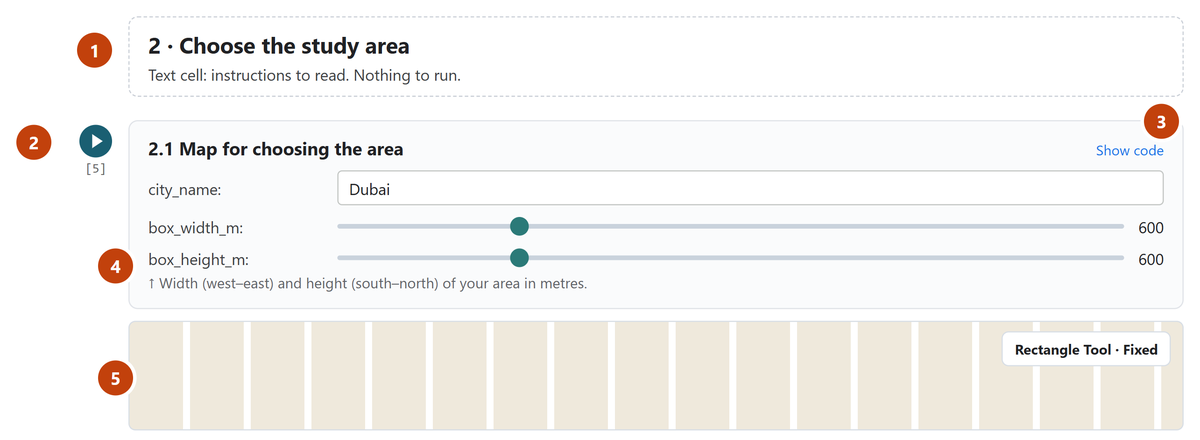

## 1 · Set-up

In [2]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
!pip install -q voxcity

## 2 · Choose the area
Run **2.1**. On the map: click **Fixed**, then click the centre of your street.

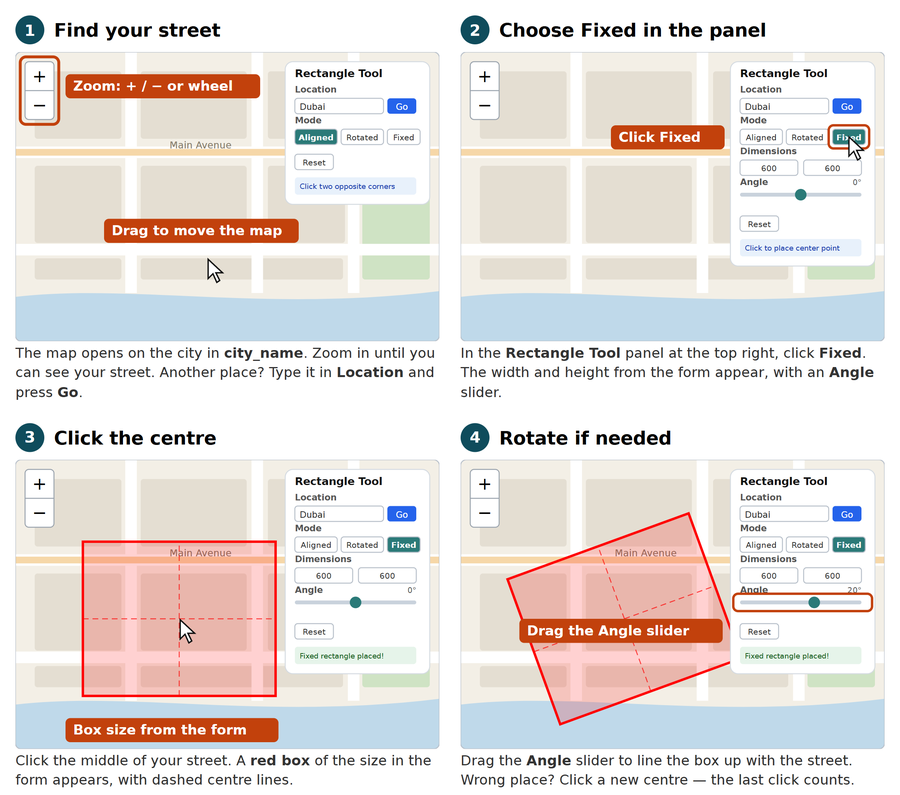

In [3]:
#@title 2.1 Map for choosing the area { display-mode: "form" }
city_name = "Singapore"  #@param {type:"string"}
box_width_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
box_height_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
from voxcity.geoprocessor.draw import create_rectangle_map
ui, rectangle_vertices = create_rectangle_map(city_name, zoom=15, width=box_width_m, height=box_height_m)
ui

In [4]:
#@title 2.2 (Alternative) Type the corners of the area { display-mode: "form" }
#@markdown Only if the map does not work. Longitude and latitude of the south-west and north-east corners.
west = -74.0160  #@param {type:"number"}
south = 40.7033  #@param {type:"number"}
east = -74.0100  #@param {type:"number"}
north = 40.7078  #@param {type:"number"}
rectangle_vertices = [(west, south), (west, north), (east, north), (east, south)]

## 3 · Build the 3D city

INFO | voxcity.voxcity.generator.api | Auto-selecting data sources for: building_source, land_cover_source, canopy_height_source, dem_source, building_complementary_source


Loading formatted geocoded file...


INFO | voxcity.voxcity.generator.api | Detected country for ROI center (-74.0130, 40.7056): United States
INFO | voxcity.voxcity.generator.api | Selected data sources:
INFO | voxcity.voxcity.generator.api | - Buildings(base)=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Buildings(comp)=Microsoft Building Footprints | https://github.com/microsoft/GlobalMLBuildingFootprints
INFO | voxcity.voxcity.generator.api | - LandCover=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Canopy=High Resolution 1m Global Canopy Height Maps v2 | https://registry.opendata.aws/dataforgood-fb-forestsv2/
INFO | voxcity.voxcity.generator.api | - DEM=USGS 3DEP 10m | https://www.usgs.gov/3d-elevation-program/about-3dep-products-services
INFO | voxcity.voxcity.generator.api | - ComplementHeight=10



  • Land Cover:  OpenStreetMap
  • Building:    OpenStreetMap
  • Canopy:      High Resolution 1m Global Canopy Height Maps v2
  • DEM:         USGS 3DEP 10m
------------------------------------------------------------
Downloading... (this may take a moment)
Fetching data from Overpass API...
  ✓ Canopy complete (1/4)
  ✓ Dem complete (2/4)
Converting data to GeoJSON format...


INFO | voxcity.voxcity.downloader.utils | File downloaded successfully and saved as output/dataset-links.csv
INFO | voxcity.voxcity.downloader.utils | File downloaded successfully and saved as output/NorthAmerica_032010110.gz
INFO | voxcity.voxcity.geoprocessor.raster.buildings | 51 of the total 557 building footprint from the base data source did not have height data.
INFO | voxcity.voxcity.geoprocessor.heights | For 0 of these building footprints without height, values from the complementary source were assigned.
INFO | voxcity.voxcity.geoprocessor.heights | For 51 of these building footprints without height, no data exist in complementary data.


  ✓ Building complete (3/4)
  ✓ Land Cover complete (4/4)
------------------------------------------------------------
All downloads complete!



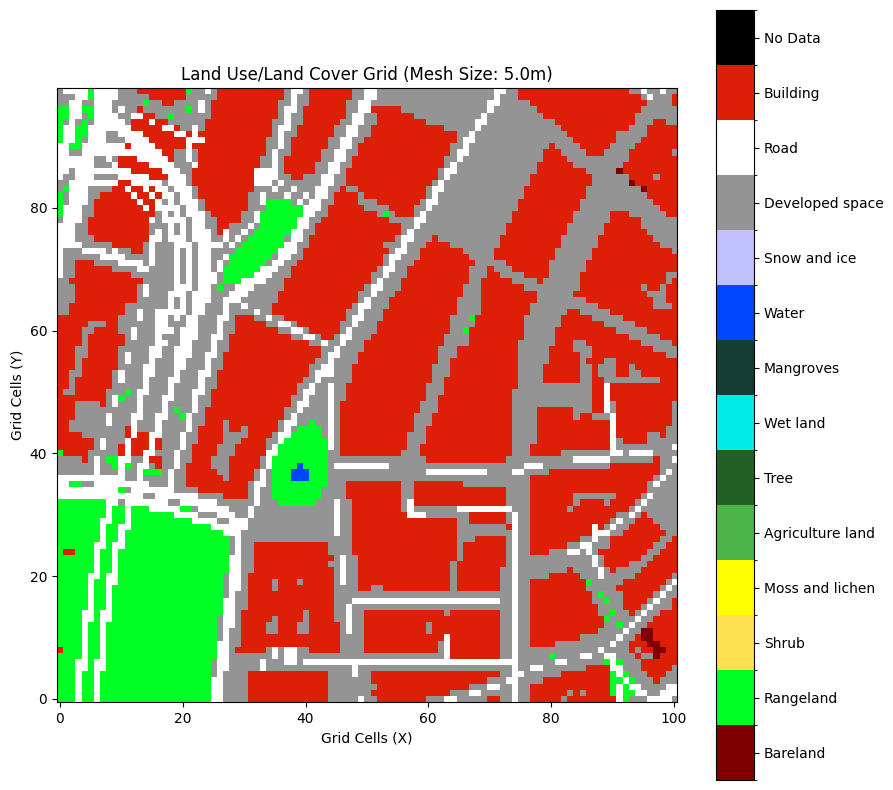

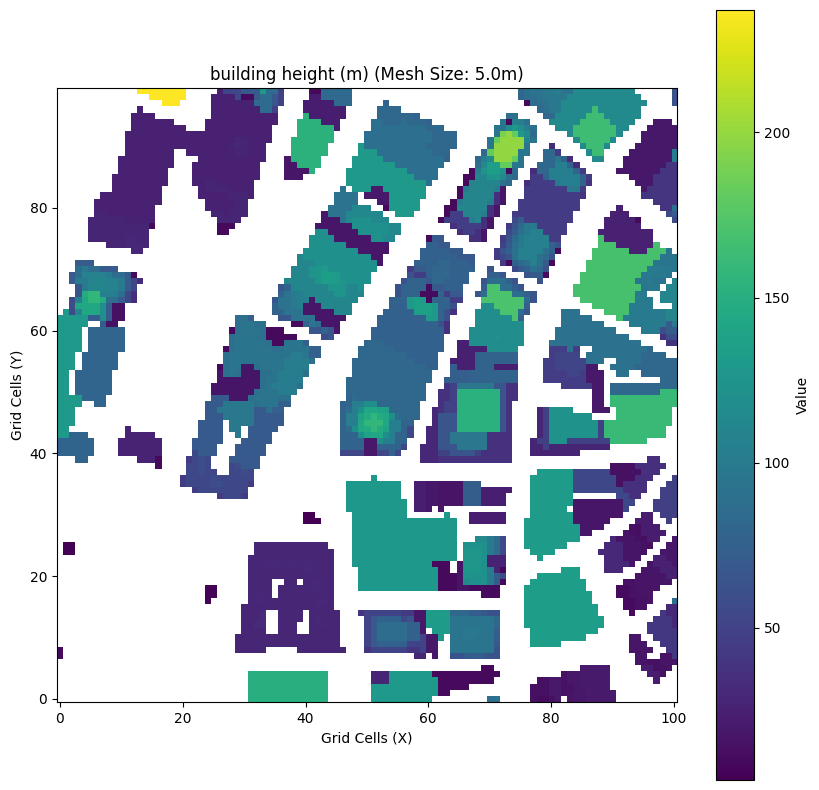

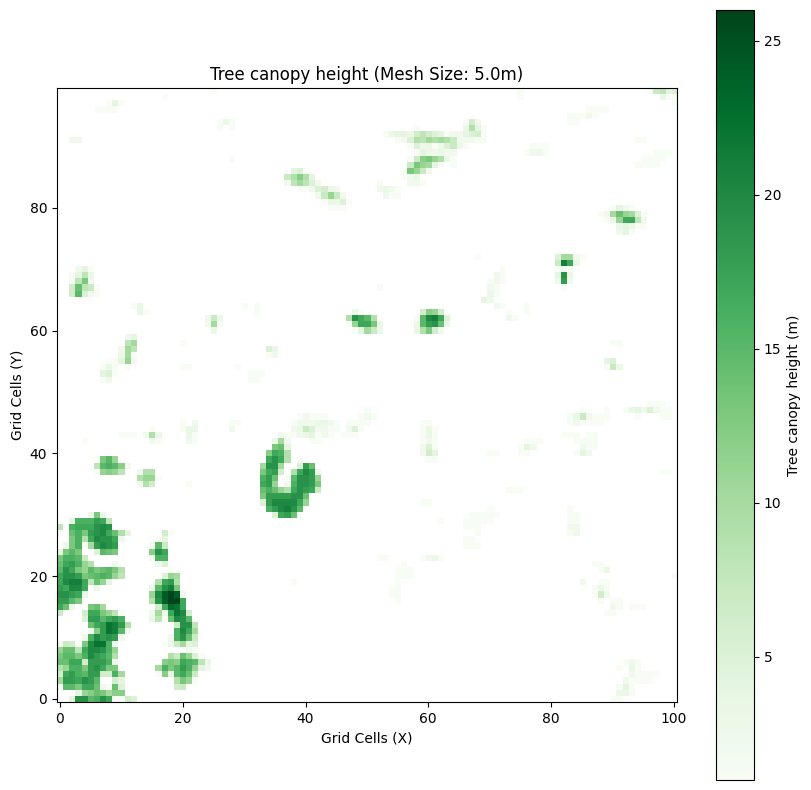

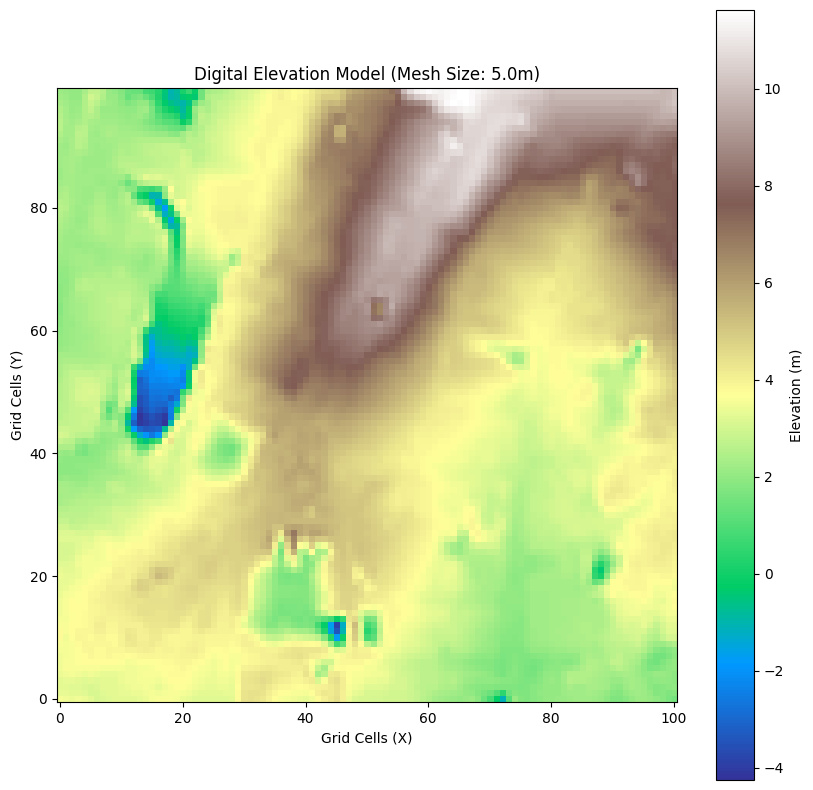

INFO | voxcity.voxcity.generator.voxelizer | Generating 3D voxel data
INFO | voxcity.voxcity.generator.voxelizer | 
Voxel Grid Semantic Codes:
  -3 : Building volume
  -2 : Tree canopy (vegetation)
  -1 : Ground/Subsurface
  >=1: Land cover class at ground surface (see Land Cover Classes)

INFO | voxcity.voxcity.generator.voxelizer | 
VoxCity Standard Land Cover Classes (1-based indices, used in voxel grids):
--------------------------------------------------
   1: Bareland           - Bare soil, rocks, desert
   2: Rangeland          - Grassland, pasture
   3: Shrub              - Shrubland, bushes
   4: Agriculture land   - Cropland, farmland
   5: Tree               - Forest, tree cover
   6: Moss and lichen    - Moss, lichen cover
   7: Wet land           - Wetland, marsh
   8: Mangrove           - Mangrove forest
   9: Water              - Water bodies
  10: Snow and ice       - Snow, ice, glaciers
  11: Developed space    - Urban areas, parking
  12: Road               - Roads, p

VoxCity results saved to output/voxcity.h5


In [5]:
#@title 3.1 Build the 3D city (1–5 minutes) { display-mode: "form" }
cube_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
from voxcity.generator import get_voxcity
voxcity = get_voxcity(rectangle_vertices, cube_size_m)

## 4 · Look at your city

In [6]:
#@title 4.1 3D view { display-mode: "form" }
from voxcity.visualizer import visualize_voxcity
visualize_voxcity(voxcity, mode="interactive", downsample=1)

## 5 · Simulations

Auto-detected regions: North_and_Central_America, USA, Europe
Fetching weather station data from Climate.OneBuilding.Org...
Scanning Canada...
Found 4296 stations in Canada
Scanning USA...
Found 13355 stations in USA
Scanning Caribbean...
Found 1943 stations in Caribbean
Scanning Europe...
Found 16286 stations in Europe

Total stations found: 35880


Downloaded EPW file for New.York-Downtown.Manhattan.Heli NY USA
Distance: 0.61 km
Station coordinates: -74.009, 40.701
WMO: 720553
Climate zone: 4A - Mixed - Humid
Data period: 2011-2018
Files saved:
- EPW: output/new.york-downtown.manhattan.heli_ny_usa.epw
- Metadata: output/new.york-downtown.manhattan.heli_ny_usa.json

Loading EPW data...
Loaded 8760 hourly records


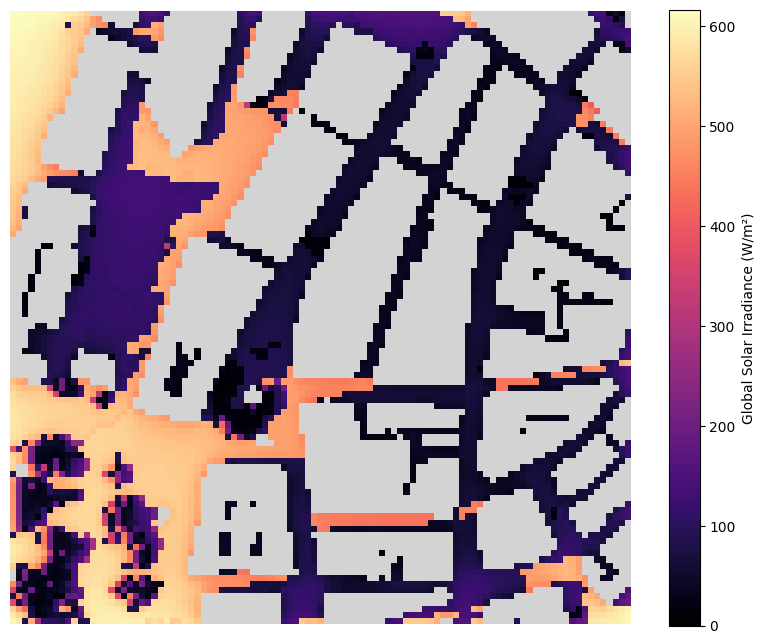

In [7]:
#@title 5.1 Sunlight at street level { display-mode: "form" }
#@markdown Uses typical weather of the nearest station (an average year), so there is no year to choose.
month = "June"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
day = 21  #@param {type:"slider", min:1, max:31, step:1}
hour = 15  #@param {type:"slider", min:6, max:19, step:1}
import calendar
m = list(calendar.month_name).index(month)
d = min(day, calendar.monthrange(2025, m)[1])   # e.g. 31 June -> 30 June
from voxcity.simulator.solar import get_global_solar_irradiance_using_epw
solar_grid = get_global_solar_irradiance_using_epw(
    voxcity,
    calc_type="instantaneous",
    calc_time=f"{m:02d}-{d:02d} {hour:02d}:00:00",   # "MM-DD HH:MM:SS"
    download_nearest_epw=True,
    view_point_height=1.5,
    colormap="magma",
)

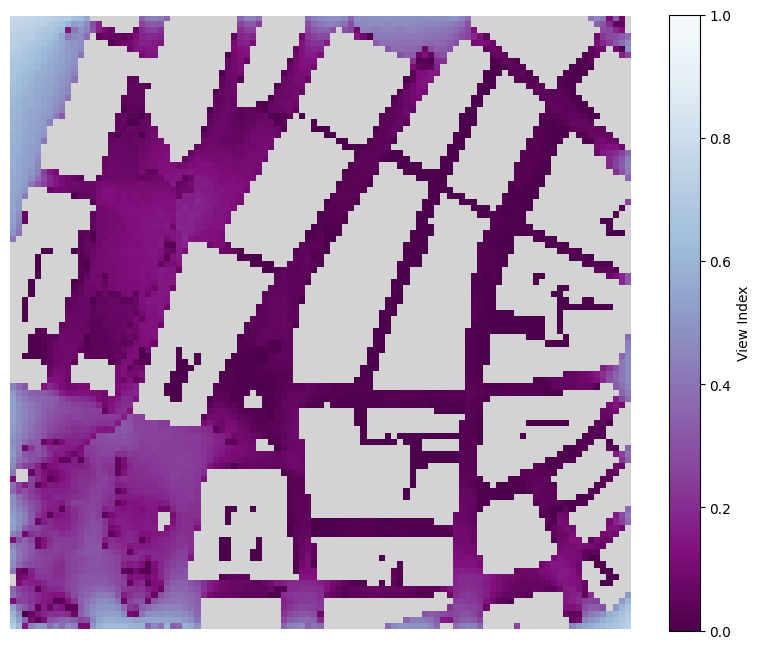

In [8]:
#@title 5.2 Sky view or green view index { display-mode: "form" }
what = "Sky"  #@param ["Sky", "Greenery"]
from voxcity.simulator.visibility import get_view_index
if what == "Sky":
    view_grid = get_view_index(voxcity, mode="sky", view_point_height=1.5, colormap="BuPu_r", elevation_min_degrees=0)
else:
    view_grid = get_view_index(voxcity, mode="green", view_point_height=1.5, colormap="viridis")

## 6 · Export
OBJ: Blender, Rhino, Twinmotion · INX: ENVI-met · VOX: MagicaVoxel

In [9]:
#@title 6.1 OBJ file { display-mode: "form" }
from voxcity.exporter.obj import export_obj
export_obj(voxcity, "output/obj", "voxcity")

INFO | voxcity.voxcity.exporter.obj | OBJ and MTL files have been generated in output/obj with the base name "voxcity".


In [10]:
#@title 6.2 INX file for ENVI-met { display-mode: "form" }
from voxcity.exporter.envimet import export_inx
export_inx(voxcity, "output/envimet", "voxcity")

In [11]:
#@title 6.3 VOX file for MagicaVoxel { display-mode: "form" }
from voxcity.exporter.magicavoxel import export_magicavoxel_vox
export_magicavoxel_vox(voxcity, "output/magicavoxel")

INFO | voxcity.voxcity.exporter.magicavoxel | Chunk 0_0_0 saved as output/magicavoxel/chunk_0_0_0.vox
INFO | voxcity.voxcity.exporter.magicavoxel | Shape: (101, 100, 50)
INFO | voxcity.voxcity.exporter.magicavoxel | 	vox files was successfully exported in output/magicavoxel


In [12]:
#@title 6.4 Download everything as one zip file { display-mode: "form" }
import shutil
from google.colab import files
files.download(shutil.make_archive("voxcity_output", "zip", "output"))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Next steps
[More tutorials](index.md) · [Questions](https://github.com/kunifujiwara/VoxCity/discussions) · [Cite the paper](https://doi.org/10.1016/j.compenvurbsys.2025.102366)